Handwritten Digit Recognition


*   Supervised Learning: Train a decision tree using images paired with their correct labels (0–9).
*   Classification: The trained model examines pixel values in previously unseen images and predicts which digit each image represents.
*   Prediction: Use the trained model to accuratly predict digits






In [ ]:
#Get imported libraries

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
from sklearn import datasets
from sklearn.tree import DecisionTreeClassifier


In [ ]:
#Load in and store handwritten digits data set

digits = datasets.load_digits()
X, y = digits['data'], digits['target']
n, d = X.shape
print("n=",n)
print("d=",d)

#Dislay snipert of raw data set
df = pd.DataFrame(data=digits.data, columns=digits.feature_names)
df.head()



n= 1797
d= 64


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


[[ 0  0  0 10 11  0  0  0]
 [ 0  0  3 16 10  0  0  0]
 [ 0  0  8 16  0  0  0  0]
 [ 0  0 12 14  0  0  0  0]
 [ 0  0 14 16 15  6  0  0]
 [ 0  0 12 16 12 15  6  0]
 [ 0  0  7 16 10 13 14  0]
 [ 0  0  0  9 13 11  6  0]]


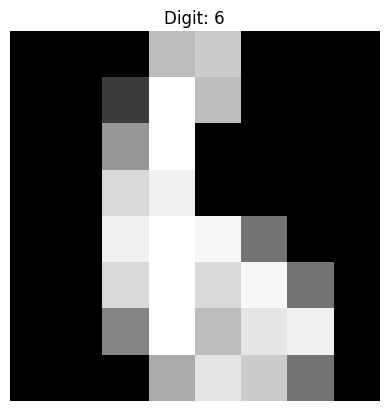

In [ ]:
#Display a random handwritten digit and its corresponding 8x8 pixel intensity matrix

idx = np.random.randint(0, n)
matrix = X[idx].reshape(8, 8)

print(matrix.astype(int))

plt.imshow(matrix, cmap="Greys_r")
plt.title(f"Digit: {y[idx]}")
plt.axis("off")
plt.show()

### Label: A digit (0-9)
### Features: 8x8 matrix per label. Each item in matrix represents a pizel. The number associated with each item represents a shade. Shade value ranged from 0-16.
### Samples: data sets includes ~180 images (samples) of each digit to train on

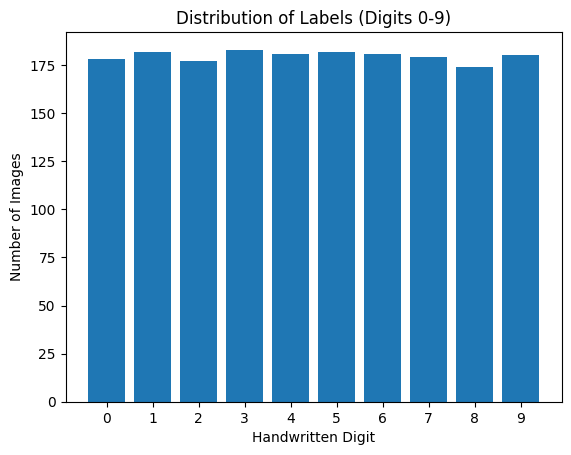

In [ ]:
counts = np.bincount(y)

plt.bar(range(10), counts)
plt.xticks(range(10))
plt.xlabel("Handwritten Digit")
plt.ylabel("Number of Images")
plt.title("Distribution of Labels (Digits 0-9)")
plt.show()

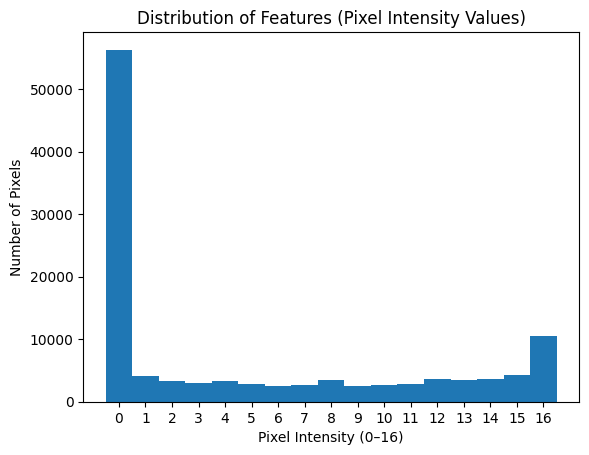

In [ ]:
plt.hist(X.flatten(), bins=np.arange(18)-0.5)

plt.xlabel("Pixel Intensity (0–16)")
plt.ylabel("Number of Pixels")
plt.title("Distribution of Features (Pixel Intensity Values)")
plt.xticks(range(17))
plt.show()

### Decision stump (depth=1)


*   Consists of only 1 (yes/no) decision



In [ ]:
stump = DecisionTreeClassifier(max_depth=1)
stump.fit(X,y)

DecisionTreeClassifier(max_depth=1)

Displays Decision Tree:
  -only 1 decision made
  -root = pixel number 36
  -decision = is pixel 36 0 or is pixel 36 1-16 (aka pixel completely black or some level of shaded)

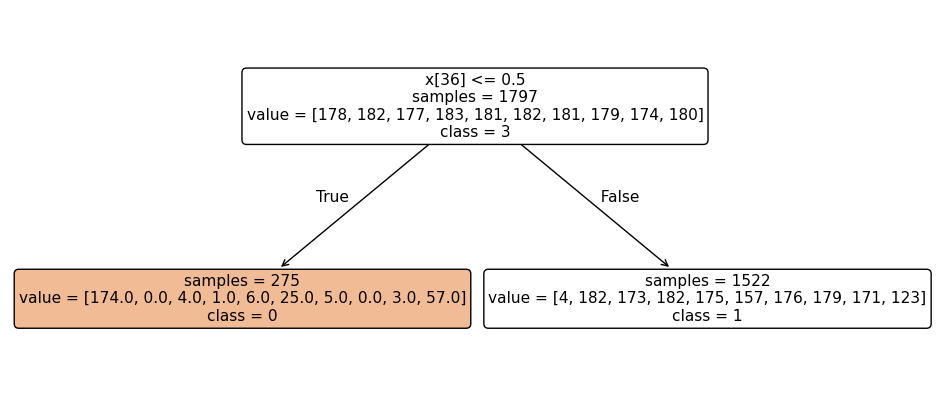

In [ ]:
plt.figure(figsize=(12, 5))
plot_tree(
    stump,
    class_names=digits.target_names.astype(str),
    filled=True,
    rounded=True,
    impurity=False
)
plt.show()

Obviously has high error rate


*   Cant make an accurate prediction when model was trained using only 1 decison



In [ ]:
yhat = stump.predict(X)
print("Error rate:", np.sum(y!=yhat)/n) # or np.mean(y!=yhat)
print(yhat)

Error rate: 0.80189204229271
[0 1 1 ... 1 1 1]


### Decision tree (depth=2)

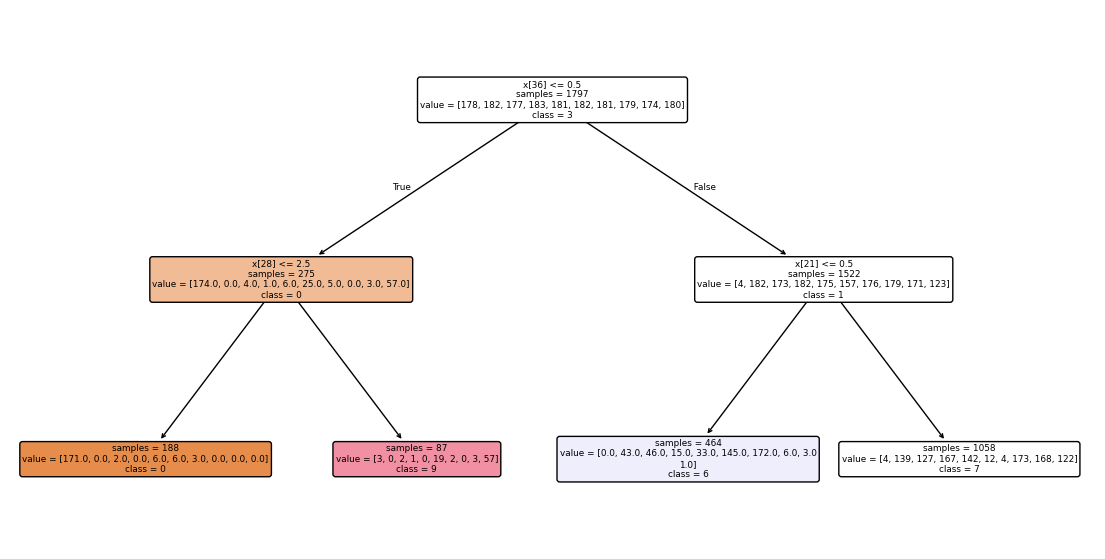

In [ ]:
tree = DecisionTreeClassifier(max_depth=2)
tree.fit(X, y)

plt.figure(figsize=(14, 7))
plot_tree(
    tree,
    class_names=digits.target_names.astype(str),
    filled=True,
    rounded=True,
    impurity=False
)
plt.show()

Error rate decreased as more levels of decision making was added


*   Trained model with error rate of ~68% is still too high to make accurate predictions though



In [ ]:
yhat = tree.predict(X)
print("Error rate:", np.sum(y!=yhat)/n) # or np.mean(y!=yhat)

Error rate: 0.6811352253756261


### How error rate changes vs. depth

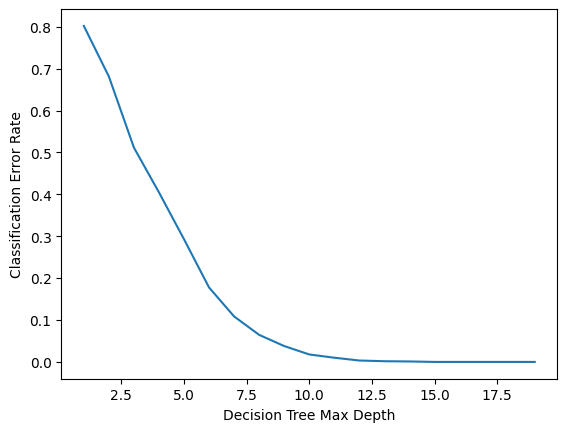

In [ ]:
errors = []
depths = range(1,20)
for max_depth in depths:
    tree = DecisionTreeClassifier(max_depth=max_depth)
    tree.fit(X,y)
    yhat = tree.predict(X)
    #store error rates for each level of depth
    errors.append(np.mean(y!=yhat))
plt.plot(depths, errors)
plt.xlabel("Decision Tree Max Depth")
plt.ylabel("Classification Error Rate");

At depth 18 the model can make predictions of the training dataset with a 0% error rate


*   Model most likely overfitting though
*   It will now struggle to accurately make predictions on random data that is not from the training dataset





In [ ]:
errors[-1]

np.float64(0.0)

### Overfitting


- With this decision tree, "training accuracy" is 1.
- It perfectly labels the data we used to make the tree.


In [ ]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.2)

tree = DecisionTreeClassifier(max_depth=20)
tree.fit(Xtrain,ytrain)
yhat = tree.predict(Xtrain)
train_err = np.mean(ytrain!=yhat)
print("Training error,", train_err)

Training error, 0.0


In [ ]:
yhat = tree.predict(Xtest)
train_err = np.mean(ytest!=yhat)
print("Test error,", train_err)

Test error, 0.1388888888888889


- Overfitting: lower accuracy on new data.
- Rules got too specific to our exact training dataset.

### Training vs. test error


*   After a certain threshold
*   Model continues improving on training data without a corresponding improvement in its ability to generalize to unseen test data




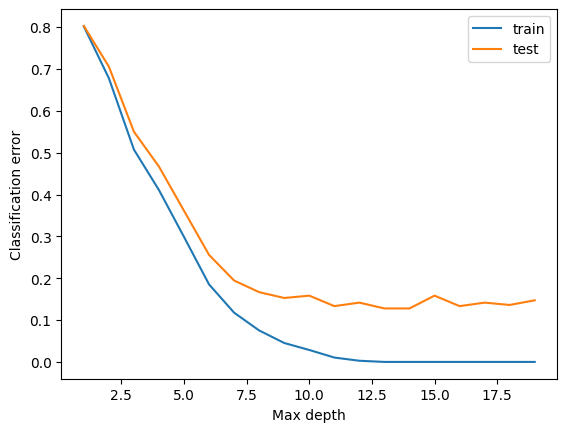

In [ ]:
train_errors = []
test_errors = []
for max_depth in depths:
    tree = DecisionTreeClassifier(max_depth=max_depth)
    tree.fit(Xtrain,ytrain)
    train_errors.append(np.mean(ytrain!=tree.predict(Xtrain)))
    test_errors.append(np.mean(ytest!=tree.predict(Xtest)))
plt.plot(depths, train_errors, label="train")
plt.plot(depths, test_errors, label="test")
plt.xlabel("Max depth")
plt.ylabel("Classification error")
plt.legend();

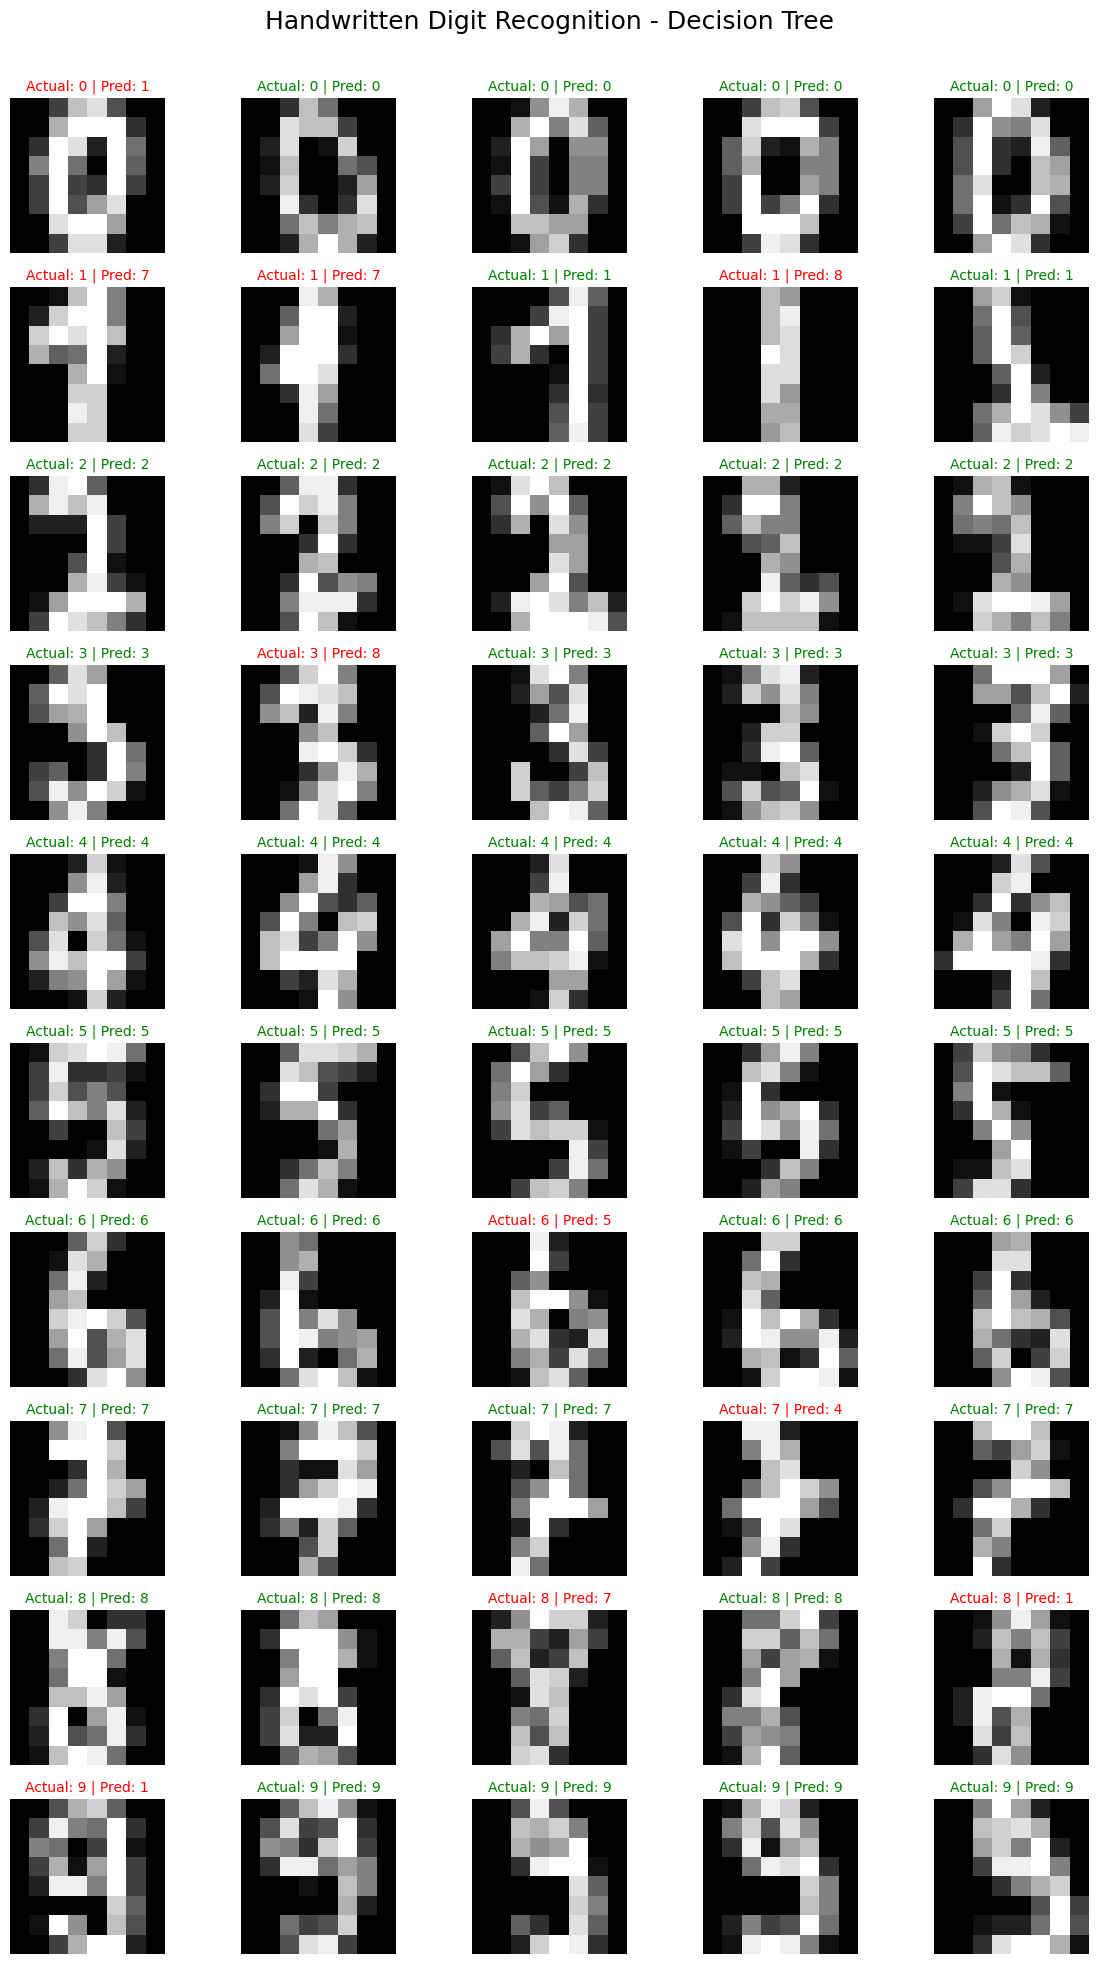

Test Accuracy: 81.11%


In [ ]:
# Display the 10 digits (0-9) and their predictions

# Load handwritten digit dataset
digits = load_digits()

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    digits.data,
    digits.target,
    test_size=0.2,
    random_state=42,
    stratify=digits.target
)

# Train decision tree
model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)

# Create a 10-row x 5-column display
fig, axes = plt.subplots(10, 5, figsize=(12, 20))

rng = np.random.default_rng(42)

for digit in range(10):

    # Find test images of this digit
    indices = np.where(y_test == digit)[0]

    # Randomly select 5 examples
    selected = rng.choice(
        indices, size=5, replace=False
    )

    for col, idx in enumerate(selected):

        # Get image and prediction
        image = X_test[idx].reshape(8, 8)
        prediction = model.predict(
            X_test[idx].reshape(1, -1)
        )[0]

        # Display image
        ax = axes[digit, col]
        ax.imshow(image, cmap="gray")

        # Green if correct, red if incorrect
        color = "green" if prediction == digit else "red"

        ax.set_title(
            f"Actual: {digit} | Pred: {prediction}",
            color=color,
            fontsize=10
        )

        ax.axis("off")

plt.suptitle(
    "Handwritten Digit Recognition - Decision Tree\n\n",
    fontsize=18
)

plt.tight_layout()
plt.show()

# Overall accuracy on unseen test images
accuracy = model.score(X_test, y_test)
print(f"Test Accuracy: {accuracy:.2%}")
